# Reading an image one patch at a time

We'll recognize a handwritten digit by reading its image as 49 small patches. This gives us a sequence task where we can see exactly what arrives at each timestep, what the neurons remember, and how the final prediction depends on earlier input. Along the way, we'll inspect a neuron's response, build and train a network, look at its mistakes, and save the learned model.

Our goal is to learn how to build and train a stateful model, rather than train a state-of-the-art classifier. We'll use a small image subset so there's time to inspect the results and try changes.

The notebook assumes basic Python and PyTorch tensor knowledge. After cloning and installing the repository, install this example's packages with `pip install -r examples/mnist/requirements.txt`. You can then open `examples/mnist/tutorial.ipynb` and run the cells in order. The neighboring `main.py` contains the complete automatic program; here we'll build the same solution with room to inspect and change it.

Source on GitHub: [notebook](https://github.com/Yegor-men/tracetorch/blob/main/examples/mnist/tutorial.ipynb) and [complete program](https://github.com/Yegor-men/tracetorch/blob/main/examples/mnist/main.py).

## 1. Preparing an image batch

MNIST gives us grayscale images with 28 rows and 28 columns, together with labels from zero to nine. We'll use `ToTensor` to represent the pixels as values between zero and one, then select 4,096 training images and 1,024 separate test images so the first run stays short.

The setup below uses two CPU threads and a fixed seed for a repeatable starting point. `DATA_ROOT` points to the shared `examples/data` folder, so other image examples can reuse the download, while `checkpoint_dir` belongs to this example. When you run the notebook normally, its working folder is `examples/mnist`.

In [1]:
from pathlib import Path
from time import perf_counter
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
import tracetorch as tt

# Keep saved figures readable regardless of the notebook editor's theme.
plt.style.use("default")
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cpu"
DATA_ROOT = Path("../data")
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)


In [2]:
def get_dataloaders(data_root, batch_size, train_samples, test_samples, seed):
    transform = transforms.ToTensor()
    train = datasets.MNIST(data_root, train=True, download=True, transform=transform)
    test = datasets.MNIST(data_root, train=False, download=True, transform=transform)
    generator = torch.Generator().manual_seed(seed)
    if train_samples:
        indices = torch.randperm(len(train), generator=generator)[:train_samples].tolist()
        train = Subset(train, indices)
    if test_samples:
        indices = torch.randperm(len(test), generator=generator)[:test_samples].tolist()
        test = Subset(test, indices)
    return (
        DataLoader(train, batch_size=batch_size, shuffle=True, generator=generator),
        DataLoader(test, batch_size=batch_size),
    )

Images: torch.Size([64, 1, 28, 28]) Labels: torch.Size([64])


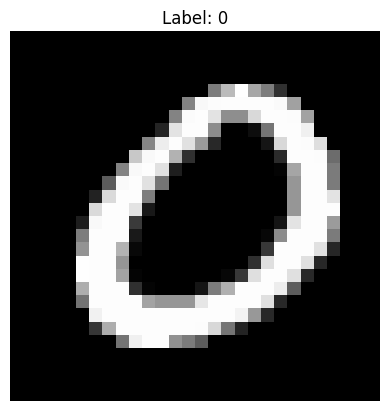

In [3]:
train_loader, test_loader = get_dataloaders(DATA_ROOT, 64, 4096, 1024, seed=0)
images, labels = next(iter(test_loader))
print("Images:", images.shape, "Labels:", labels.shape)
plt.imshow(images[0, 0], cmap="gray")
plt.title(f"Label: {labels[0].item()}")
plt.axis("off")
plt.show()

We can now see both the images and their labels. The tensor has shape `[64, 1, 28, 28]`: 64 images, one channel, and the two spatial dimensions. Training will use the training subset, while the test images let us examine whether the model learns something it can use on images outside that subset.

## 2. Reading the image as patches

Instead of presenting all 784 pixels at once, we'll take a 4 × 4 window and move it four pixels at a time. That gives seven positions across and seven down, or 49 timesteps with 16 pixels each. The patches don't overlap, so we retain every pixel while changing when the model gets to see it. We'll read from left to right, then continue on the next row.

In [4]:
def images_to_patch_sequence(images):
    """Convert [B, 1, 28, 28] images to [49, B, 16] patches in row order."""
    if images.ndim != 4 or tuple(images.shape[1:]) != (1, 28, 28):
        raise ValueError("Expected MNIST images with shape [B, 1, 28, 28]")
    patches = F.unfold(images, kernel_size=4, stride=4)
    return patches.permute(2, 0, 1).contiguous()

Sequence: torch.Size([49, 64, 16])
First patch:
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


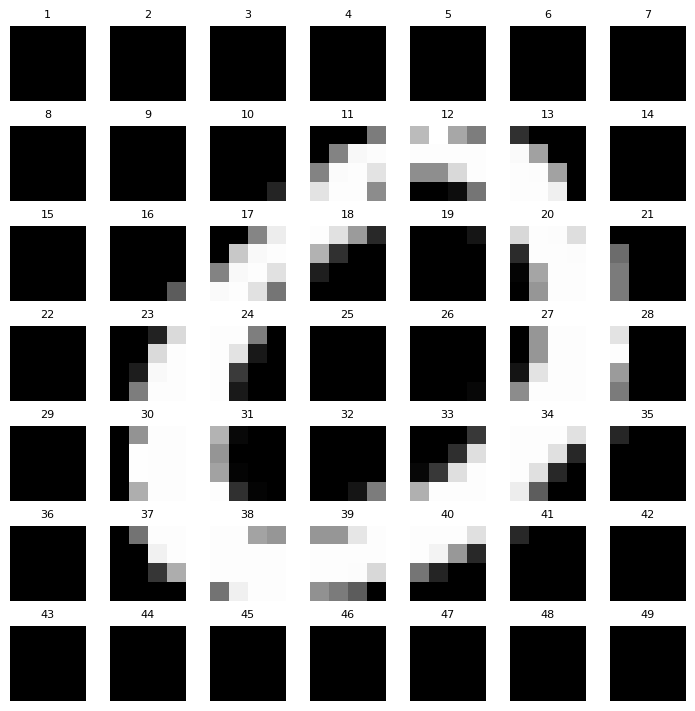

In [5]:
sequence = images_to_patch_sequence(images)
print("Sequence:", sequence.shape)
print("First patch:")
print(sequence[0, 0].reshape(4, 4))

fig, axes = plt.subplots(7, 7, figsize=(7, 7), layout="constrained")
for index, axis in enumerate(axes.flat):
    axis.imshow(sequence[index, 0].reshape(4, 4), cmap="gray", vmin=0, vmax=1)
    axis.set_title(str(index + 1), fontsize=8)
    axis.axis("off")
plt.show()

`unfold` collects the patches as `[B, 16, 49]`, and `permute` moves time to the front, giving `[49, B, 16]`. Each call to our model will therefore receive one `[B, 16]` patch batch. The empty corner patches are part of the image too; we haven't added noise or converted the pixels into input spikes.

You can check the ordering by displaying `sequence[7, 0].reshape(4, 4)`. It should be the leftmost patch in the second row of patches, which is where reading continues after the first seven positions.

## 3. Observing a neuron's memory

Before building the classifier, let's look at what one neuron does with a short input pulse. A leaky integrator stores a membrane value $m$ and combines its previous value with the current input $i_t$:

$$m_t = \beta m_{t-1} + i_t.$$

Here $0 < \beta < 1$ is the decay. A larger decay keeps more of the previous membrane, so input can continue to influence the neuron after the pulse ends. `tt.snn.LI` returns this continuous membrane directly.

Our hidden layers will use LIB, or leaky integrate-and-binary-fire, which adds a positive threshold $\theta$ and a firing output $s_t$:

$$m_t = \beta(m_{t-1} - \theta s_{t-1}) + i_t,$$
$$s_t = 1 \text{ if } m_t \geq \theta, \quad 0 \text{ otherwise}.$$

Notice the previous output in the reset term: an event affects the membrane on the next timestep, before decay. We subtract the threshold instead of immediately setting the membrane to zero. Both states begin at zero, and these numerical membrane values don't have assigned physical voltage units.

In [6]:
def record_neuron_response(inputs, beta):
    """Record a fixed LIB neuron's membrane and firing after each input."""
    neuron = tt.snn.LIB(1, beta=beta, threshold=1.0, learn_beta=False, learn_threshold=False)
    membrane, spikes = [], []
    with torch.no_grad():
        for value in inputs:
            output = neuron(value.reshape(1, 1))
            membrane.append(neuron.mem.item())
            spikes.append(output.item())
    return torch.tensor(membrane), torch.tensor(spikes)

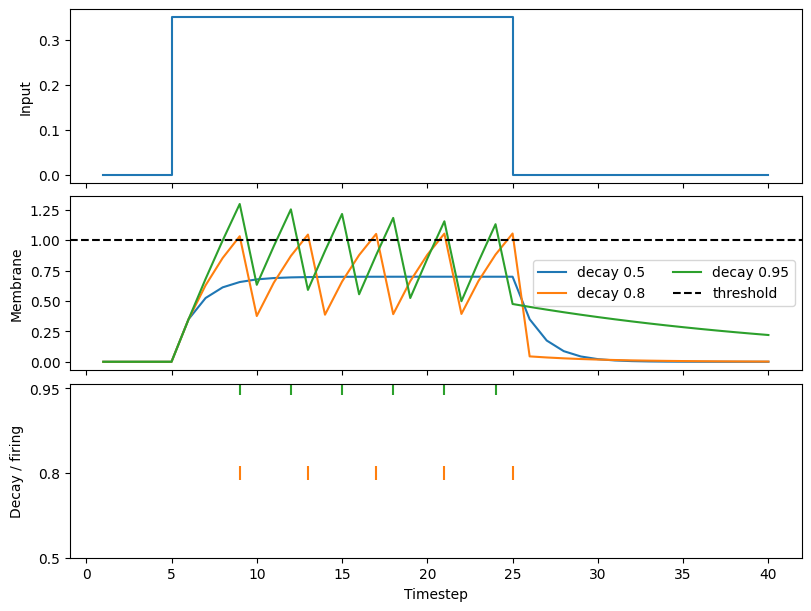

In [7]:
inputs = torch.cat([torch.zeros(5), torch.full((20,), 0.35), torch.zeros(15)])
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True, layout="constrained")
axes[0].step(range(1, 41), inputs)
axes[0].set_ylabel("Input")
for row, beta in enumerate((0.5, 0.8, 0.95)):
    membrane, spikes = record_neuron_response(inputs, beta)
    line, = axes[1].plot(range(1, 41), membrane, label=f"decay {beta}")
    times = torch.arange(1, 41)[spikes.bool()]
    axes[2].scatter(times, torch.full_like(times, row), marker="|", s=100, color=line.get_color())
axes[1].axhline(1, linestyle="--", color="black", label="threshold")
axes[1].set_ylabel("Membrane")
axes[1].legend(ncol=2)
axes[2].set_yticks([0, 1, 2], ["0.5", "0.8", "0.95"])
axes[2].set_ylabel("Decay / firing")
axes[2].set_xlabel("Timestep")
plt.show()

With decay 0.5, the repeated input approaches $0.35/(1-0.5)=0.7$, so it never reaches threshold 1. The larger decays keep enough history to fire, and their membrane drops on the following timesteps show the delayed reset. After the pulse ends, the remaining memory fades rather than disappearing at once.

Try reducing the pulse from 0.35 to 0.2. Before rerunning the cell, use the steady value $i/(1-\beta)$ to predict which decays can still lead to firing. This connects the curves to the update equation we'll use inside the model.

## 4. Building the network

We'll use two LIB layers with 256 neurons each, with linear projections to mix features before each neuron layer. Each hidden neuron starts with the default decay of 0.9 and can learn its decay during training. The last linear projection produces ten contributions, one for each digit, and an LI layer collects them as decaying class evidence. We can think of each patch as adding evidence to ten buckets, with the hidden memories influencing what that patch contributes.

In [8]:
class PatchSNN(tt.Model):
    """Process one [B, 16] patch and return ten scores for each image."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(16, 256),
            tt.snn.LIB(256),
            nn.Linear(256, 256),
            tt.snn.LIB(256),
            nn.Linear(256, 10),
            tt.snn.LI(10, beta=0.9, beta_rank=0, learn_beta=False),
        )

    def forward(self, patch):
        return self.net(patch)

One patch enters with shape `[B, 16]`, passes through the two `[B, 256]` hidden stages, and leaves as `[B, 10]` scores. Each forward call handles only that patch; the neuron layers retain their own states for the next call.

For the final LI, we deliberately use the same fixed decay of 0.9 for every class. The task gives us no reason to assign a different recency rule to a five than a six, so this example keeps that rule shared (`beta_rank=0`) and fixed (`learn_beta=False`). If $e_t$ is the vector from the last linear projection, the final scores are

$$z_T = \sum_{t=1}^{T}0.9^{T-t}e_t.$$

LI returns this weighted sum. Dividing by the common sum of weights would turn it into a weighted average without changing which class wins. We don't need a projection after LI because its ten values already correspond to the ten classes.

By inheriting from `tt.Model`, we can reset states across the whole network, including the layers inside `nn.Sequential`. We won't need to pass a separate collection of membrane values through the linear modules.

## 5. Processing a complete image

The patches from one image share a history, but different image batches don't. We'll reset before beginning a batch and then keep the states through all 49 patches. A reset sets the states to `None`, so the first patch allocates zeros with the current batch shape, device and data type.

In [9]:
def forward_sequence(model, sequence):
    # Patches from one image share memory. The next batch contains new images.
    model.reset_states()
    for patch in sequence:
        logits = model(patch)
    return logits

We return only the final scores because that's where this task makes its prediction. Earlier patches still affect those scores through the stored states; resetting inside the patch loop would remove that connection.

The scores are called *logits*. Cross-entropy compares all ten of them with the correct label, so we pass the raw scores directly rather than applying softmax first. For a correct class $c$ and scores $z_j$, the loss for one image is

$$\mathcal L = -\log\frac{e^{z_c}}{\sum_{j=0}^{9}e^{z_j}}.$$

Increasing the correct class's score relative to the others reduces this loss, even when the predicted class hasn't changed yet.

## 6. Training one batch

A hard firing event has zero derivative away from its threshold, which would stop ordinary backpropagation from providing a useful gradient there. LIB's default firing function keeps the binary forward output but uses a smooth derivative in the backward pass. This is a *surrogate gradient*.

For membrane distance $z=m-\theta$, the smooth function and its derivative are

$$g(z)=\frac{1}{1+e^{-4z}}, \qquad g'(z)=4g(z)(1-g(z)).$$

Let's plot the hard output alongside that smooth function and the derivative we'll use to train.

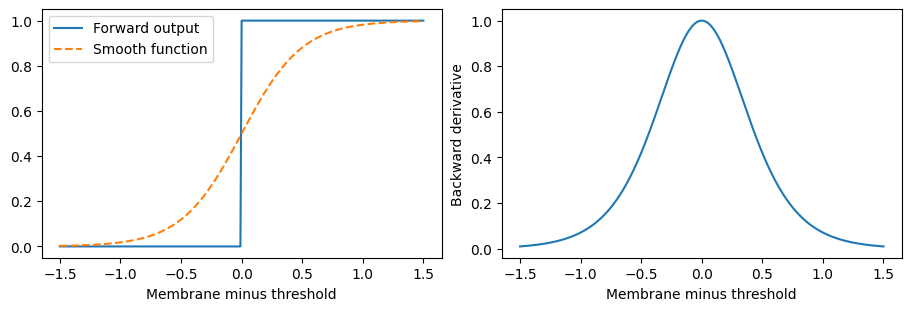

In [10]:
distance = torch.linspace(-1.5, 1.5, 301)
smooth = tt.snn.spike_fn.smooth(distance)
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
axes[0].plot(distance, tt.snn.spike_fn.deterministic(distance), label="Forward output")
axes[0].plot(distance, smooth, linestyle="--", label="Smooth function")
axes[0].legend()
axes[1].plot(distance, 4 * smooth * (1 - smooth))
axes[1].set_ylabel("Backward derivative")
for axis in axes:
    axis.set_xlabel("Membrane minus threshold")
plt.show()

The derivative is largest near threshold, where a small membrane change is most relevant to firing. When we call `loss.backward()`, PyTorch follows these derivatives through the sequence, including the state updates that connected earlier patches to the final output.

The function below brings those steps together: it clears accumulated parameter gradients, processes the image sequence, calculates the final-output loss, and updates the weights. Clearing gradients and resetting sequence memory are separate operations, so both appear in the code. We detach the returned values because we'll use them for logging after the update, without keeping their completed training calculations.

In [11]:
def train_batch(model, images, labels, optimizer):
    """Update weights once, using the final output of each image sequence."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    sequence = images_to_patch_sequence(images)
    logits = forward_sequence(model, sequence)
    loss = F.cross_entropy(logits, labels)
    loss.backward()
    optimizer.step()
    return loss.detach(), logits.detach()

In [12]:
torch.manual_seed(0)
model = PatchSNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
batch_images, batch_labels = next(iter(train_loader))
batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
with torch.no_grad():
    before = F.cross_entropy(forward_sequence(model, images_to_patch_sequence(batch_images)), batch_labels).item()
train_batch(model, batch_images, batch_labels, optimizer)
with torch.no_grad():
    after = F.cross_entropy(forward_sequence(model, images_to_patch_sequence(batch_images)), batch_labels).item()
print(f"Batch loss: {before:.3f} -> {after:.3f}")

Batch loss: 2.431 -> 2.411


The loss on this batch falls after the update, which lets us check the training procedure on data we've just seen. A single update isn't guaranteed to improve a batch, though, and fitting that batch alone wouldn't tell us how the model behaves on other images. We'll now train over the selected subset and follow the separate test results.

## 7. Training over the selected images

An epoch means one pass through our training subset. During evaluation, we'll disable gradient recording and leave the weights unchanged, while still resetting states between independent image batches. The helper returns mean loss and the fraction of correct predictions so we can follow both confidence and classification.

In [13]:
def run_epoch(model, dataloader, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total_correct = total_count = 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        if training:
            loss, logits = train_batch(model, images, labels, optimizer)
        else:
            with torch.no_grad():
                sequence = images_to_patch_sequence(images)
                logits = forward_sequence(model, sequence)
                loss = F.cross_entropy(logits, labels)
        total_loss += loss.item() * labels.numel()
        total_correct += (logits.argmax(-1) == labels).sum().item()
        total_count += labels.numel()
    model.reset_states()
    return total_loss / total_count, total_correct / total_count

In [14]:
torch.manual_seed(0)
train_loader, test_loader = get_dataloaders(DATA_ROOT, 64, 4096, 1024, seed=0)
model = PatchSNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss, accuracy = run_epoch(model, test_loader, device)
history = {"train_loss": [], "train_accuracy": [], "test_loss": [loss], "test_accuracy": [accuracy]}
print(f"Before training: test loss={loss:.3f}, accuracy={accuracy:.1%}")
started = perf_counter()
for epoch in range(1, 11):
    train_loss, train_accuracy = run_epoch(model, train_loader, device, optimizer)
    loss, accuracy = run_epoch(model, test_loader, device)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["test_loss"].append(loss)
    history["test_accuracy"].append(accuracy)
    print(f"Epoch {epoch}: test loss={loss:.3f}, accuracy={accuracy:.1%}")
print(f"Training and evaluation: {perf_counter() - started:.1f}s")

Before training: test loss=2.387, accuracy=10.3%
Epoch 1: test loss=1.861, accuracy=34.3%
Epoch 2: test loss=1.617, accuracy=44.8%
Epoch 3: test loss=1.491, accuracy=49.4%
Epoch 4: test loss=1.386, accuracy=51.0%
Epoch 5: test loss=1.315, accuracy=55.9%
Epoch 6: test loss=1.304, accuracy=55.3%
Epoch 7: test loss=1.205, accuracy=57.0%
Epoch 8: test loss=1.185, accuracy=59.3%
Epoch 9: test loss=1.203, accuracy=58.0%
Epoch 10: test loss=1.095, accuracy=61.9%
Training and evaluation: 14.4s


We restart the model and data loaders for this run so the one-batch experiment doesn't change its starting point. With the reference settings, ten epochs improve test accuracy from 10.3% to about 61.9%, while test loss falls from 2.387 to about 1.095. Exact values can vary between environments, but both measures should show a clear change from the untrained model.

## 8. Interpreting the learning curves

Let's put the epoch results into plots so we can see how quickly learning begins and where progress becomes less steady.

In [15]:
def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    axes[0].plot(epochs, history["train_loss"], label="Training")
    axes[0].plot([0, *epochs], history["test_loss"], label="Test")
    axes[0].set_ylabel("Mean cross-entropy loss")
    axes[1].plot(epochs, [100 * value for value in history["train_accuracy"]], label="Training")
    axes[1].plot([0, *epochs], [100 * value for value in history["test_accuracy"]], label="Test")
    axes[1].set_ylabel("Correct predictions (%)")
    axes[1].set_ylim(0, 100)
    for axis in axes:
        axis.set_xlabel("Epoch (0 = before training)")
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle("Learning from 49-patch image sequences")
    return fig

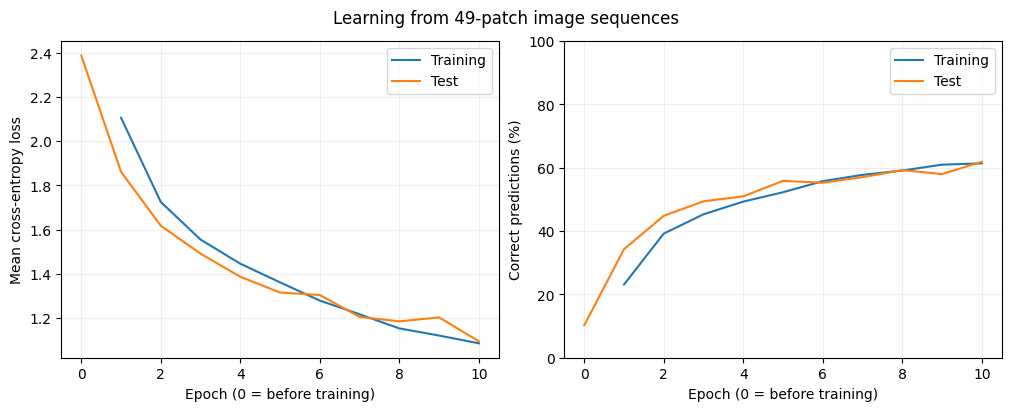

In [16]:
plot_history(history)
plt.show()

Test epoch 0 represents the untrained model. Falling test loss and improving test accuracy tell us the network is learning information it can use on unseen images, even though neither curve has to improve at every epoch.

Training accuracy is averaged while the weights change, whereas test accuracy uses the fixed weights at the end of the epoch. That's one reason the test result can be higher than the training average in a short run.

The averages don't show which digits cause trouble, so we'll also inspect individual predictions. The next figure deliberately includes errors alongside correct answers.

In [17]:
def plot_predictions(model, images, labels, device):
    model.eval()
    with torch.no_grad():
        logits = forward_sequence(model, images_to_patch_sequence(images.to(device)))
    predicted = logits.argmax(-1).cpu()
    model.reset_states()
    # Include errors so the figure shows what this short run has not learned.
    correct = (predicted == labels).nonzero().flatten()[:8]
    incorrect = (predicted != labels).nonzero().flatten()[:8]
    selected = torch.cat([correct, incorrect]).tolist()
    fig, axes = plt.subplots(4, 4, figsize=(8, 8), layout="constrained")
    for axis in axes.flat:
        axis.axis("off")
    for axis, index in zip(axes.flat, selected):
        axis.imshow(images[index, 0], cmap="gray", vmin=0, vmax=1)
        color = "#166534" if predicted[index] == labels[index] else "#b91c1c"
        axis.set_title(f"Label {labels[index].item()} / predicted {predicted[index].item()}",
                       color=color, fontsize=9)
    fig.suptitle("Test examples: correct predictions and errors")
    return fig

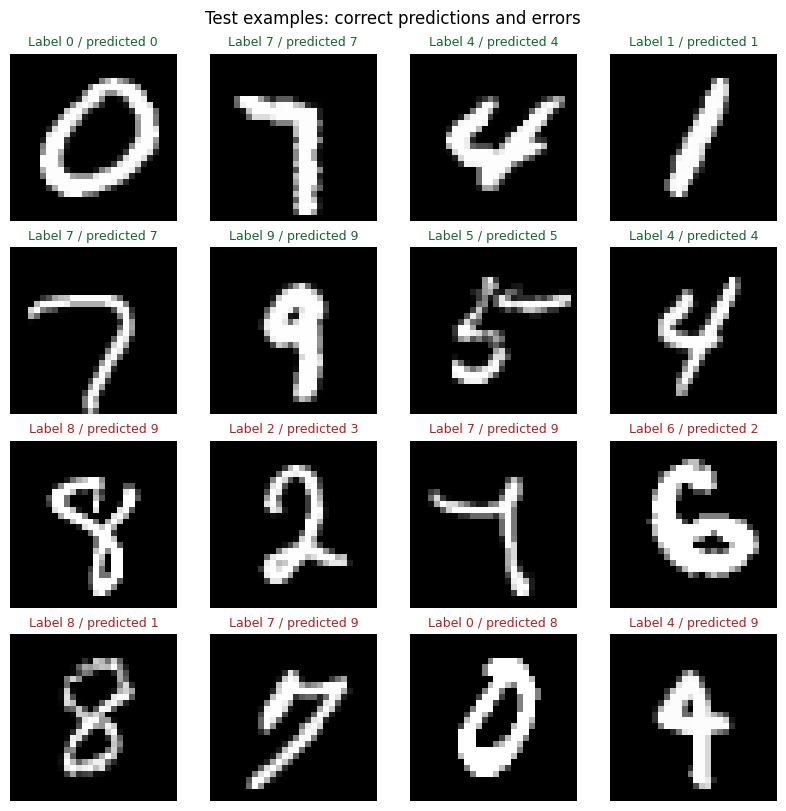

In [18]:
images, labels = next(iter(test_loader))
plot_predictions(model, images, labels, device)
plt.show()

The figure chooses up to eight correct and eight incorrect predictions from one batch, so its proportions aren't an estimate of overall accuracy. Looking at a mistaken pair can help us ask which image patches distinguish the two shapes, and whether useful evidence arrives early or late in the sequence.

### Watching the readout during an image

We can make that question more concrete by recording the scores after each patch. This is an inspection of the trained model: we'll still use only the final scores for the task's prediction and loss.

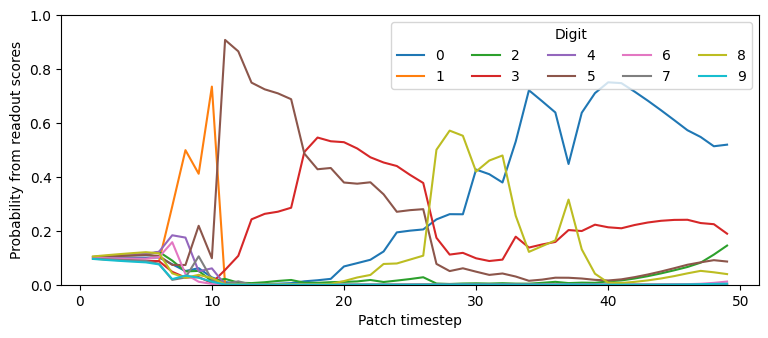

In [19]:
model.eval()
model.reset_states()
scores = []
with torch.no_grad():
    for patch in images_to_patch_sequence(images[:1].to(device)):
        scores.append(model(patch)[0].cpu())
model.reset_states()
probabilities = torch.stack(scores).softmax(-1)
plt.figure(figsize=(9, 3.5))
for digit in range(10):
    plt.plot(range(1, 50), probabilities[:, digit], label=str(digit))
plt.xlabel("Patch timestep")
plt.ylabel("Probability from readout scores")
plt.legend(title="Digit", ncol=5)
plt.ylim(0, 1)
plt.show()

Here we use softmax to display the scores as probabilities, while training continues to pass logits directly to cross-entropy. The preferred digit can change as evidence arrives, and confidence needn't grow steadily from patch to patch. Even a blank patch updates the states through decay, biases and any remaining firing history; it isn't a pause in the calculation.

## 9. Removing memory to see its effect

We've treated each image as a sequence, but how much does the trained prediction actually depend on earlier patches? To check, we'll keep the weights and reset before every patch instead of before every image batch. That changes how the model uses its state without retraining it.

Normal sequence: 61.9%; reset every patch: 10.8%


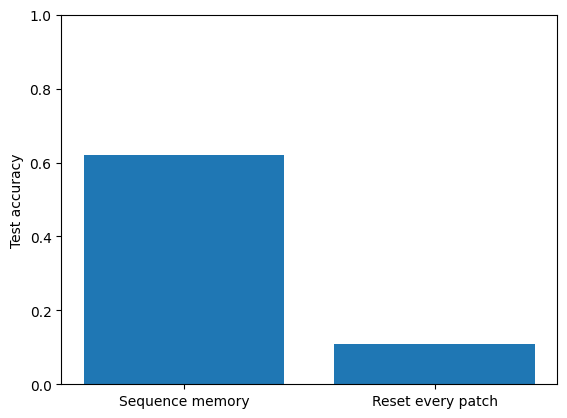

In [20]:
model.eval()
correct = count = 0
with torch.no_grad():
    for images, labels in test_loader:
        for patch in images_to_patch_sequence(images.to(device)):
            model.reset_states()
            logits = model(patch)
        correct += (logits.argmax(-1).cpu() == labels).sum().item()
        count += labels.numel()
model.reset_states()
without_memory = correct / count
print(f"Normal sequence: {history['test_accuracy'][-1]:.1%}; reset every patch: {without_memory:.1%}")
plt.bar(["Sequence memory", "Reset every patch"], [history["test_accuracy"][-1], without_memory])
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.show()

Resetting every patch drops the reference accuracy from 61.9% to around chance. The final patch is often blank, and without earlier history the network loses much of the evidence it needs to distinguish the digits. This experiment makes the sequence boundary visible in the result, rather than just treating reset as a required line of code.

For another experiment, return to normal sequence resets and increase either the training subset or the epoch count. Changing one setting at a time makes it easier to connect the new curves and individual errors to the change you made.

## 10. Saving and reloading the model

Our learned weights describe how to classify an image, while the hidden states describe the particular patches read so far. Because the next image starts from reset states, we'll save the weights and optimizer in `checkpoints/model.pt` without saving an image's temporary memory.

In [21]:
checkpoint = checkpoint_dir / "model.pt"
torch.save({"weights": model.state_dict(), "optimizer": optimizer.state_dict(), "completed_epochs": 10}, checkpoint)
restored = PatchSNN().to(device)
restored.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True)["weights"])
restored.eval()
with torch.no_grad():
    example = images_to_patch_sequence(images[:1].to(device))
    expected = forward_sequence(model, example)
    actual = forward_sequence(restored, example)
print("Restored prediction:", actual.argmax(-1).item())
print("Maximum score difference:", (actual - expected).abs().max().item())

Restored prediction: 0
Maximum score difference: 0.0


The restored model produces the same scores when we start both models from reset states and give them the same image. For a task that continues an unfinished stream, we would also save hidden states and the next input position; the Alice language-model example works through that case.

The reference training and evaluation take roughly 16 seconds on CPU, excluding downloads and figures. You can run the complete workflow with `python examples/mnist/main.py --device cpu`; it reuses `examples/data` and writes figures and `checkpoints/model.pt` inside `examples/mnist`.